# Ready, Set, Bet: a probability laboratory
**MATH 180 · Strategies of Problem Solving · Task 3**

How can a horse that moves less often still be a good bet?

In this activity, you will count small experiments exactly, simulate entire
races, and use expected value to compare bets. Finish by designing an
experiment around a question your group finds interesting.

| Part | Your job |
| :--- | :--- |
| 1 · One roll | Describe the sample space and predict each horse's position. |
| 2 · Two rolls | Account for the repeat-roll bonus. |
| 3 · Many races | Estimate win, place, and show probabilities. |
| 4 · Betting decisions | Compare payouts and update predictions during a race. |
| 5 · Your investigation | Ask a question, collect data, and explain what you found. |


### Your group
Double-click this text cell to fill it in. Press **Shift + Enter** to finish editing.

**Names:** …  
**Date:** …

Work together. One person can run the notebook while another checks the reasoning;
switch roles as you go. Everyone should help interpret the results.


## Getting started in Google Colab

1. Open [Google Colab](https://colab.research.google.com/) and choose
   **File → Upload notebook** to upload this `.ipynb` file.
2. Save your working notebook to Drive. If you opened a shared version, use
   **File → Save a copy in Drive**. Rename your copy to include your group's names.
3. Work from top to bottom. Click a code cell's **▶** button, or press
   **Shift + Enter**, to run it. The first run may take a moment to connect.
4. Write in the **Your response** text cells. You can use ordinary sentences,
   bullet points, tables, or mathematics such as `$1/6$`.

**Predict before running a check.** Save **Run all** for your final check.
The setup and race-engine cells only need to be run once per session.
If Colab reconnects and reports an undefined name, rerun those cells and then
the experiment you need.

Everything needed is included here. Use a standard Python runtime;
no package installation, file uploads, or Drive mounting are needed to run the activity.


## The race model

Roll two independent, fair six-sided dice. Their total selects a horse,
which advances one space.

| Color | Horses | Extra spaces for a bonus |
| :--- | :--- | ---: |
| Blue | 2/3, 4, 10, 11/12 | 3 |
| Orange | 5, 9 | 2 |
| Red | 6, 8 | 1 |
| Black | 7 | 0 |

Repeated selections of the **same horse** form pairs: the second, fourth,
sixth, … selections in a consecutive run receive the bonus. Thus 3 followed
by 2 earns the 2/3 horse a bonus, but the third consecutive selection does not.
The 11/12 horse works the same way.

Horses start at position 0. The race stops immediately when one horse reaches
position 15; positions are capped at the finish line.

**Win** means first. **Place** means at most one horse is strictly ahead.
**Show** means at most two are strictly ahead. Tied horses share a rank:
if several horses tie for second, they all place and show, and horses behind
them do not show. The winner also places and shows.

We use the base race rules. VIP effects and card-specific bets are outside
this activity. The [publisher's rulebook](https://www.alderac.com/wp-content/uploads/2025/04/ReadySetBet_BaseGame_Rulebook_Optimized.pdf)
is the reference for movement and betting.


In [ ]:
#@title Setup — run this first
from itertools import product
from fractions import Fraction
from html import escape
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HORSES = ["2/3", "4", "5", "6", "7", "8", "9", "10", "11/12"]
HORSE_INDEX = {name: i for i, name in enumerate(HORSES)}
BONUS = np.array([3, 3, 2, 1, 0, 1, 2, 3, 3])
DICE_TO_HORSE = np.array([-1, -1, 0, 0, 1, 2, 3, 4, 5, 6, 7, 8, 8])
COLORS = ["#3b82f6", "#3b82f6", "#f59e0b", "#ef4444", "#334155",
          "#ef4444", "#f59e0b", "#3b82f6", "#3b82f6"]

plt.rcParams.update({
    "figure.dpi": 120, "font.size": 11, "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#334155", "text.color": "#0f172a",
    "axes.titleweight": "bold", "figure.facecolor": "white",
})
pd.set_option("display.max_columns", 12)

class NotebookTable:
    def __init__(self, html):
        self.html = html

    def _repr_html_(self):
        return self.html

def show_table(frame, caption, formats=None):
    # Native notebook HTML display; no optional table-formatting packages.
    if isinstance(formats, str):
        formatters = {column: formats.format for column in frame.columns}
    elif formats:
        formatters = {column: template.format for column, template in formats.items()}
    else:
        formatters = None
    html = frame.to_html(formatters=formatters, border=0, escape=True)
    html = html.replace('<th>', '<th style="background:#eff6ff;color:#0f172a;'
                        'padding:7px 10px;text-align:right;border-bottom:1px solid #cbd5e1">')
    html = html.replace('<td>', '<td style="padding:7px 10px;text-align:right;'
                        'border-bottom:1px solid #e2e8f0">')
    display(NotebookTable(
        '<div style="overflow-x:auto;margin:12px 0">'
        '<div style="font-size:16px;font-weight:600;color:#0f172a;padding:8px 0">'
        + escape(caption) + '</div>' + html + '</div>'
    ))

print("Setup complete. Now run the race-engine cell below.")


Setup complete. Now run the race-engine cell below.


In [ ]:
#@title Race engine — run once; open the code if you are curious
def start_positions(initial_positions=None, finish=15):
    '''Accept a horse-name dictionary, or a list in HORSES order.'''
    if initial_positions is None:
        values = [0] * len(HORSES)
    elif isinstance(initial_positions, dict):
        if set(initial_positions) != set(HORSES):
            raise ValueError("Include each of the nine horse names exactly once.")
        values = [initial_positions[h] for h in HORSES]
    else:
        values = initial_positions
    raw = np.asarray(values)
    if raw.shape != (9,) or not np.issubdtype(raw.dtype, np.number):
        raise ValueError("Provide nine numerical starting positions.")
    if not np.all(np.isfinite(raw)) or not np.all(raw == np.floor(raw)):
        raise ValueError("Starting positions must be whole numbers.")
    if np.any(raw < 0) or np.any(raw >= finish):
        raise ValueError("Each starting position must be between 0 and finish - 1.")
    return raw.astype(np.int64)

def validate_history(previous_horse, previous_streak):
    if not isinstance(previous_streak, (int, np.integer)) or previous_streak < 0:
        raise ValueError("The previous streak must be a nonnegative whole number.")
    if previous_horse is None:
        if previous_streak != 0:
            raise ValueError("Use streak 0 when no previous horse is supplied.")
        return -1
    if previous_horse not in HORSE_INDEX or previous_streak < 1:
        raise ValueError("Choose a valid previous horse and a streak of at least 1.")
    return HORSE_INDEX[previous_horse]

def trace_rolls(totals, finish=15, use_bonus=True):
    '''Follow a short specified history, beginning at the starting line.'''
    positions = np.zeros(9, dtype=int)
    last_horse, streak = -1, 0
    records = []
    for roll_number, total in enumerate(totals, 1):
        if not isinstance(total, (int, np.integer)) or not 2 <= total <= 12:
            raise ValueError("Every dice total must be a whole number from 2 to 12.")
        horse = int(DICE_TO_HORSE[total])
        streak = streak + 1 if horse == last_horse else 1
        extra = int(BONUS[horse]) if use_bonus and streak % 2 == 0 else 0
        positions[horse] = min(finish, positions[horse] + 1 + extra)
        records.append({"Roll": roll_number, "Total": total, "Horse": HORSES[horse],
                        "Move": 1 + extra, "New position": int(positions[horse])})
        last_horse = horse
        if positions[horse] == finish:
            break
    return {
        "positions": dict(zip(HORSES, positions.tolist())),
        "previous_horse": HORSES[last_horse] if last_horse >= 0 else None,
        "previous_streak": streak,
        "trace": pd.DataFrame(records),
    }

def finish_events(positions):
    # For each horse, count other horses that are strictly ahead of it.
    ahead = (positions[:, None, :] > positions[:, :, None]).sum(axis=2)
    return {"win": ahead == 0, "place": ahead < 2, "show": ahead < 3}

def simulate_races(n_races=50000, finish=15, initial_positions=None,
                   previous_horse=None, previous_streak=0, seed=180,
                   use_bonus=True):
    '''Simulate independent continuations of one fully specified race state.'''
    if not isinstance(n_races, (int, np.integer)) or not 1 <= n_races <= 200000:
        raise ValueError("Choose a whole number of races from 1 to 200,000.")
    if not isinstance(finish, (int, np.integer)) or not 1 <= finish <= 100:
        raise ValueError("Choose a whole-number finish position from 1 to 100.")
    if not isinstance(seed, (int, np.integer)) or seed < 0:
        raise ValueError("Choose a nonnegative whole-number seed.")
    initial = start_positions(initial_positions, finish)
    previous = validate_history(previous_horse, previous_streak)
    rng = np.random.default_rng(seed)
    positions = np.tile(initial, (n_races, 1))
    rolls = np.zeros(n_races, dtype=int)
    last = np.full(n_races, previous, dtype=int)
    streak = np.full(n_races, previous_streak, dtype=int)
    active = np.arange(n_races)

    # Move one selected horse in every unfinished race on each pass.
    while active.size:
        totals = rng.integers(1, 7, size=(active.size, 2)).sum(axis=1)
        horse = DICE_TO_HORSE[totals]
        run = np.where(horse == last[active], streak[active] + 1, 1)
        extra = BONUS[horse] * (run % 2 == 0) if use_bonus else 0
        positions[active, horse] = np.minimum(
            finish, positions[active, horse] + 1 + extra
        )
        rolls[active] += 1
        last[active], streak[active] = horse, run
        active = active[positions[active, horse] < finish]

    return {
        "positions": positions, "rolls": rolls,
        "winner": positions.argmax(axis=1),
        **finish_events(positions),
        "n_races": n_races, "finish": finish, "seed": seed,
        "use_bonus": use_bonus, "initial_positions": initial,
        "previous_horse": previous_horse, "previous_streak": previous_streak,
    }

def probability_table(results):
    return pd.DataFrame({
        name.title(): results[name].mean(axis=0)
        for name in ("win", "place", "show")
    }, index=pd.Index(HORSES, name="Horse"))

def show_probabilities(results, caption):
    # Rows match the table requested in the original activity.
    show_table(probability_table(results).T, caption, "{:.1%}")

def plot_probabilities(results):
    table = probability_table(results)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
    for ax, event in zip(axes, ["Win", "Place", "Show"]):
        estimates = table[event].to_numpy()
        margin = 2 * np.sqrt(estimates * (1 - estimates) / results["n_races"])
        ax.bar(HORSES, estimates, color=COLORS, yerr=margin, capsize=3,
               edgecolor="white", linewidth=0.8)
        ax.set_title(event)
        ax.set_xlabel("Horse")
        ax.tick_params(axis="x", labelrotation=35)
        ax.grid(axis="y", alpha=0.18)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Estimated probability")
    fig.suptitle(f"{results['n_races']:,} simulated races · finish at {results['finish']}",
                 fontsize=15, fontweight="bold")
    fig.tight_layout()
    plt.show()

def plot_start(positions):
    values = [positions[h] for h in HORSES]
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.barh(HORSES, values, color=COLORS)
    ax.invert_yaxis()
    ax.set_xlim(0, 15.8)
    ax.axvline(15, color="#475569", linestyle="--")
    ax.set_xticks(range(0, 16))
    ax.set_xlabel("Position")
    ax.set_title("The observed race state")
    for i, value in enumerate(values):
        ax.text(value + 0.12, i, str(value), va="center")
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()

def compare_win_probabilities(before, after):
    p1 = before["win"].mean(axis=0)
    p2 = after["win"].mean(axis=0)
    x = np.arange(9)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - 0.19, p1, 0.38, label="From the starting line", color="#94a3b8")
    ax.bar(x + 0.19, p2, 0.38, label="From the observed state", color=COLORS)
    ax.set_xticks(x, HORSES)
    ax.set_ylabel("Estimated win probability")
    ax.set_xlabel("Horse")
    ax.set_title("How does new information change our predictions?")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()

print("Race engine ready. Start with Part 1.")


Race engine ready. Start with Part 1.


---
# 1 · One roll: count before you simulate

Begin with all horses at the starting line. Roll the two dice once.

1. Use an **ordered pair of die faces** to describe one outcome. Write the
   sample space compactly and find its size.
2. What is the probability of any one of these outcomes? Explain your answer.
3. For each horse, count how many outcomes move it.
4. What is each horse's **expected position** after this roll?

Be careful: a die-face pair, a dice total, and a selected horse are three
different ways to describe an outcome. Are their probabilities all equal?


### Your response · Part 1

**Sample space and size:** …

**Probability of one ordered pair:** …

| Horse | 2/3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11/12 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Number of die-face pairs | … | … | … | … | … | … | … | … | … |
| Expected position | … | … | … | … | … | … | … | … | … |

**Why is expected position the same as the probability of being selected here?** …


In [ ]:
#@title Check Part 1 — run after making your predictions
one_roll_pairs = list(product(range(1, 7), repeat=2))
one_roll_counts = np.zeros(9, dtype=int)
for die_1, die_2 in one_roll_pairs:
    one_roll_counts[DICE_TO_HORSE[die_1 + die_2]] += 1
p_one_roll = one_roll_counts / len(one_roll_pairs)
one_roll_check = pd.DataFrame({
    "Die-face pairs": one_roll_counts,
    "Probability (exact)": [str(Fraction(int(c), len(one_roll_pairs)))
                            for c in one_roll_counts],
    "Expected position": p_one_roll,
}, index=pd.Index(HORSES, name="Horse"))
print(f"There are {len(one_roll_pairs)} equally likely ordered pairs.")
show_table(one_roll_check, "One roll: exact counts",
           {"Expected position": "{:.4f}"})


There are 36 equally likely ordered pairs.


,Die-face pairs,Probability (exact),Expected position
Horse,,,
2/3,3,1/12,0.0833
4,3,1/12,0.0833
5,4,1/9,0.1111
6,5,5/36,0.1389
7,6,1/6,0.1667
8,5,5/36,0.1389
9,4,1/9,0.1111
10,3,1/12,0.0833
11/12,3,1/12,0.0833


---
# 2 · Two rolls: the bonus matters

Reset the horses to position 0 and roll the pair of dice twice.

1. Describe one outcome using **four die faces**, grouped into the first
   and second rolls. How many outcomes are there, and what is the probability
   of each?
2. What is the probability that a specified horse is selected on **both** rolls?
3. Find the expected position of every horse after two rolls. Account for its
   two ordinary moves and its possible bonus.
4. Is the expected position exactly twice its one-roll expected position?
   Which horse is an exception to the pattern?

Test your understanding: what happens when the totals are **3, then 2**?
What about **6, then 6**? For two rolls, the race cannot yet finish.


### Your response · Part 2

**Sample space, size, and probability of one outcome:** …

**Probability of selecting horse $h$ twice:** …

| Horse | 2/3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11/12 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Expected position after two rolls | … | … | … | … | … | … | … | … | … |

**My explanation of the bonus term:** …


In [ ]:
#@title Check Part 2 — enumerate every four-die outcome
position_totals = np.zeros(9, dtype=int)
outcome_count = 0
for d1, d2, d3, d4 in product(range(1, 7), repeat=4):
    first_horse = int(DICE_TO_HORSE[d1 + d2])
    second_horse = int(DICE_TO_HORSE[d3 + d4])
    position_totals[first_horse] += 1
    position_totals[second_horse] += 1
    if first_horse == second_horse:
        position_totals[second_horse] += BONUS[second_horse]
    outcome_count += 1

two_roll_means = position_totals / outcome_count
two_roll_check = pd.DataFrame({
    "Twice the one-roll mean": 2 * p_one_roll,
    "Bonus contribution": BONUS * p_one_roll**2,
    "Two-roll mean (exact)": [str(Fraction(int(s), outcome_count))
                              for s in position_totals],
    "Two-roll mean": two_roll_means,
}, index=pd.Index(HORSES, name="Horse"))
print(f"Counted all {outcome_count:,} equally likely four-die outcomes.")
show_table(two_roll_check, "Two rolls: exact expected positions", {
    "Twice the one-roll mean": "{:.4f}",
    "Bonus contribution": "{:.4f}", "Two-roll mean": "{:.4f}",
})
show_table(trace_rolls([3, 2])["trace"], "Example: totals 3, then 2")


Counted all 1,296 equally likely four-die outcomes.


,Twice the one-roll mean,Bonus contribution,Two-roll mean (exact),Two-roll mean
Horse,,,,
2/3,0.1667,0.0208,3/16,0.1875
4,0.1667,0.0208,3/16,0.1875
5,0.2222,0.0247,20/81,0.2469
6,0.2778,0.0193,385/1296,0.2971
7,0.3333,0.0000,1/3,0.3333
8,0.2778,0.0193,385/1296,0.2971
9,0.2222,0.0247,20/81,0.2469
10,0.1667,0.0208,3/16,0.1875
11/12,0.1667,0.0208,3/16,0.1875


,Roll,Total,Horse,Move,New position
0,1,3,2/3,1,1
1,2,2,2/3,4,5


### Explain the formula

Write $p_h$ for the probability that a roll selects horse $h$, and $b_h$
for its extra bonus spaces. The calculation above suggests

$$\mathbb{E}[\text{position of horse }h\text{ after two rolls}]
  = 2p_h + b_h p_h^2.$$

Explain why each term appears. In particular, identify where the independence
of the two rolls is used. Then check that the formula agrees with your exact counts.

**Your explanation:** …


---
# 3 · Many races: turn frequencies into probability estimates

Now reset the horses and let entire races run to the finish line.

**Before running:** predict which horse will win most often. Will horses with
the largest one-roll expected moves also win most often? What might the bonus change?

**Your prediction and reasons:** …

The simulation reports

$$\widehat{P}(\text{horse $h$ wins}) = \frac{\text{number of races won by $h$}}{\text{number of simulated races}}
$$

Place and show are estimated in the same way. The tables produced below are
your record of the probabilities; **you do not need to recopy them by hand**.


In [ ]:
#@title Choose your experiment size
#@markdown Start with 50,000 races. Use 1,000 to explore quickly, then increase the count.
N_RACES = 50000 #@param {type:"integer"}
#@markdown Reusing a seed reproduces an experiment. Changing it produces a different sample.
SEED = 180 #@param {type:"integer"}
if not isinstance(N_RACES, int) or not 1 <= N_RACES <= 200000:
    raise ValueError("Set N_RACES to a whole number between 1 and 200,000.")
if not isinstance(SEED, int) or SEED < 0:
    raise ValueError("Set SEED to a nonnegative whole number.")
print(f"Ready to simulate {N_RACES:,} races with seed {SEED}.")


Ready to simulate 50,000 races with seed 180.


Horse,2/3,4,5,6,7,8,9,10,11/12
Win,4.7%,4.8%,11.1%,18.3%,22.2%,18.5%,11.2%,4.5%,4.7%
Place,12.5%,12.9%,25.8%,39.1%,47.6%,39.2%,25.3%,12.6%,12.7%
Show,20.3%,21.1%,38.3%,54.9%,65.5%,55.0%,37.8%,20.5%,20.6%


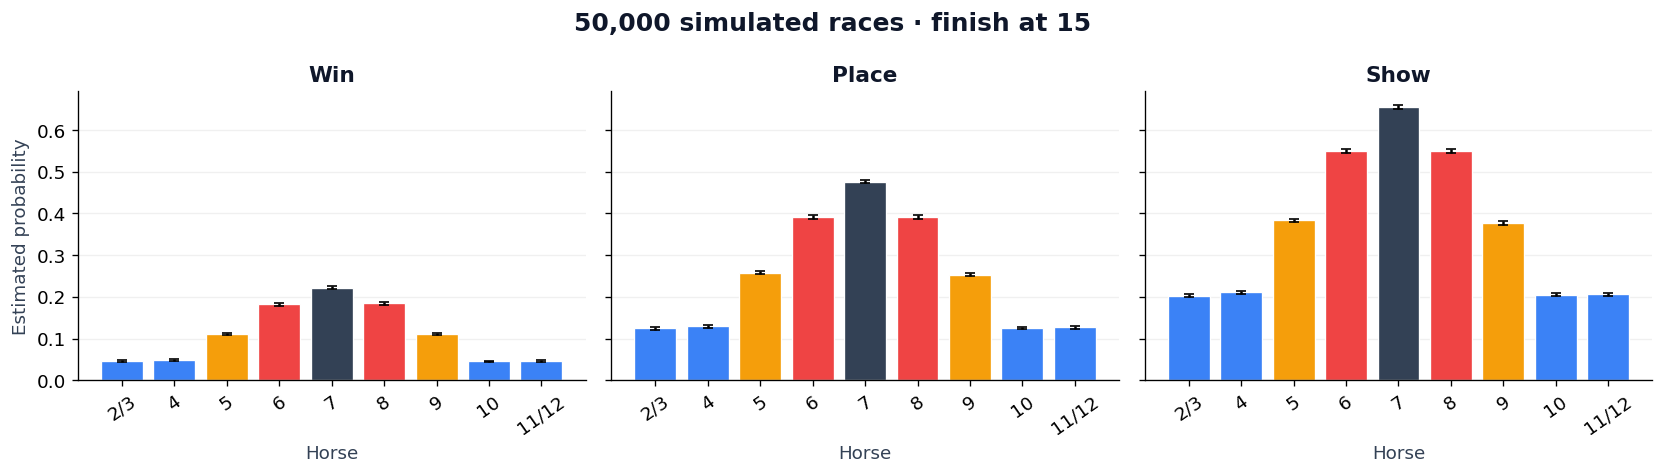

Sums of estimated probabilities:
Win      1.000
Place    2.277
Show     3.340


In [ ]:
#@title Run the races from the starting line
baseline = simulate_races(n_races=N_RACES, seed=SEED)
show_probabilities(baseline, f"Starting line · {N_RACES:,} simulated races")
plot_probabilities(baseline)
totals = probability_table(baseline).sum()
print("Sums of estimated probabilities:")
print(totals.round(3).to_string())


### Your response · Part 3

1. Which horse won most often? Did this match your prediction?
2. Does the estimated win distribution look symmetric? Which horses should
   have exactly the same true probabilities, and why might their estimates differ?
3. Why should the win probabilities add to 1? Why can the place and show
   probabilities add to **more than** 2 and 3?
4. Change the seed and rerun the two cells above. Which conclusions remain
   stable? Try a smaller race count, then restore your larger count.

**Our observations and explanations:** …

The graph's small error bars are approximately two standard errors of the
estimated probabilities. They indicate sampling variability, not mistakes in
the rules or a guarantee that the estimates are exact.


---
# 4 · Betting decisions: probability is only part of the story
## A. Compare expected gains

For a bet with success probability $p$, let

- $c$ be the number on your bet token;
- $m$ be the spot's printed payout multiplier;
- $\ell$ be its printed losing penalty, entered as a **nonnegative** number.

A success earns $cm$ chips; a failure loses $\ell$ chips. The token is a
multiplier, not a stake that you subtract from both outcomes. In particular,
the losing penalty **does not scale with the token's value**.

$$\mathbb{E}[\text{gain}] = p(cm) - (1-p)\ell.$$

Assume you have enough chips to pay the full penalties and have no VIP effects.
We compare available board spots for one race; maximizing expected gain does
not describe how variable the actual gains may be.

**Try one by hand.** The 2/3 horse's rightmost Win spot pays $9c$ on success
and loses 2 chips on failure. Use your simulated win probability to calculate
the expected gain for a **5 token**, and then a **2 token**.

**Your calculations:** …


### Build your table of available bets

The editable cell below starts with **seven example spots from the base board**,
including Win, Place, Show, and the four fixed side bets. It is a starting
comparison, **not the complete betting board**.

Before choosing a strategy, add other spots from your group's board. Include
at least two other horses and compare different kinds of bets. For each new
row, supply a unique spot ID, the bet type, the horse (for Win/Place/Show),
the multiplier, the losing penalty, and whether the spot is still open.
Set **Open** to `False` for a spot another player has taken.

The rankings only compare the open spots you enter. To claim a best bet on the
entire board, include every available spot in the scope of your claim.


In [ ]:
#@title Editable payout table — expand it using your board
# Columns: unique spot ID, bet type, horse, win multiplier, losing penalty, open?
# Bet types: Win, Place, Show, Blue wins, Orange wins, Red wins, 7 fifth or worse
# For side bets, the Horse entry is an empty string.
SPOTS = pd.DataFrame([
    ["23-S2", "Show",             "2/3", 4, 3, True],
    ["23-P2", "Place",            "2/3", 5, 3, True],
    ["23-W3", "Win",              "2/3", 9, 2, True],
    ["blue",  "Blue wins",        "",    5, 1, True],
    ["orange","Orange wins",     "",    3, 1, True],
    ["red",   "Red wins",         "",    2, 1, True],
    ["7-low", "7 fifth or worse", "",    4, 0, True],
    # Add more rows here. Separate rows with commas.
], columns=["Spot", "Bet", "Horse", "Multiplier", "Loss", "Open"])
show_table(SPOTS.set_index("Spot"), "Your recorded betting spots")


,Bet,Horse,Multiplier,Loss,Open
Spot,,,,,
23-S2,Show,2/3,4,3,True
23-P2,Place,2/3,5,3,True
23-W3,Win,2/3,9,2,True
blue,Blue wins,,5,1,True
orange,Orange wins,,3,1,True
red,Red wins,,2,1,True
7-low,7 fifth or worse,,4,0,True


In [ ]:
#@title Betting helpers — run once
def bet_event(results, bet, horse):
    if bet in {"Win", "Place", "Show"}:
        if horse not in HORSE_INDEX:
            raise ValueError("For Win, Place, or Show, enter a horse name from HORSES.")
        return results[bet.lower()][:, HORSE_INDEX[horse]]
    groups = {"Blue wins": [0, 1, 7, 8], "Orange wins": [2, 6],
              "Red wins": [3, 5]}
    if bet in groups:
        return np.isin(results["winner"], groups[bet])
    if bet == "7 fifth or worse":
        final = results["positions"]
        # Four or more horses must be strictly ahead of the 7 horse.
        return (final > final[:, [HORSE_INDEX["7"]]]).sum(axis=1) >= 4
    raise ValueError(f"Unknown bet type: {bet!r}. Use a type listed above the table.")

def rank_bets(results, spots, token_value=5):
    required = {"Spot", "Bet", "Horse", "Multiplier", "Loss", "Open"}
    if not required.issubset(spots.columns):
        raise ValueError("Keep all six columns in the payout table.")
    if spots["Spot"].duplicated().any():
        raise ValueError("Give each physical spot a unique ID.")
    if not all(isinstance(v, (bool, np.bool_)) for v in spots["Open"]):
        raise ValueError("Use True or False in the Open column.")
    if not isinstance(token_value, (int, np.integer)) or not 1 <= token_value:
        raise ValueError("Use a positive whole number for the token.")
    rows = []
    for spot in spots[spots["Open"]].to_dict("records"):
        m, loss = float(spot["Multiplier"]), float(spot["Loss"])
        if not np.isfinite(m + loss) or m < 0 or loss < 0:
            raise ValueError("Multipliers and losing penalties must be nonnegative numbers.")
        p = bet_event(results, spot["Bet"], spot["Horse"]).mean()
        rows.append({
            "Spot": spot["Spot"], "Bet": spot["Bet"], "Horse": spot["Horse"],
            "Probability": p, "Win gain": token_value * m,
            "Loss": loss, "Expected gain": p * token_value * m - (1 - p) * loss,
        })
    if not rows:
        raise ValueError("Mark at least one recorded spot as open.")
    return pd.DataFrame(rows).set_index("Spot").sort_values(
        "Expected gain", ascending=False, kind="stable"
    )

def show_bet_ranking(results, spots, token_value, caption):
    table = rank_bets(results, spots, token_value)
    show_table(table, caption, {"Probability": "{:.1%}", "Win gain": "{:.0f}",
                               "Loss": "{:.0f}", "Expected gain": "{:+.3f}"})
    return table

def rank_pairs(results, spots, first_token=5, second_token=4):
    first = rank_bets(results, spots, first_token)
    second = rank_bets(results, spots, second_token)
    rows = []
    for first_spot in first.index:
        for second_spot in second.index:
            if first_spot != second_spot:
                rows.append({
                    f"{first_token} token spot": first_spot,
                    f"{second_token} token spot": second_spot,
                    "Combined expected gain": first.loc[first_spot, "Expected gain"]
                                              + second.loc[second_spot, "Expected gain"],
                })
    if not rows:
        raise ValueError("Two tokens require at least two different open spots.")
    return pd.DataFrame(rows).sort_values(
        "Combined expected gain", ascending=False, kind="stable"
    ).reset_index(drop=True)

print("Betting helpers ready.")


Betting helpers ready.


In [ ]:
#@title Rank one-token bets from the starting line
#@markdown Try 5, then 2. Rerun this cell after editing and running the payout table.
TOKEN_VALUE = 5 #@param [2, 3, 4, 5] {type:"raw"}
baseline_ranking = show_bet_ranking(
    baseline, SPOTS, TOKEN_VALUE,
    f"Starting line · {TOKEN_VALUE} token · recorded open spots only"
)


,Bet,Horse,Probability,Win gain,Loss,Expected gain
Spot,,,,,,
7-low,7 fifth or worse,,20.8%,20,0,+4.159
blue,Blue wins,,18.8%,25,1,+3.877
red,Red wins,,36.8%,10,1,+3.044
orange,Orange wins,,22.3%,15,1,+2.566
23-S2,Show,2/3,20.3%,20,3,+1.662
23-P2,Place,2/3,12.5%,25,3,+0.490
23-W3,Win,2/3,4.7%,45,2,+0.201


In [ ]:
#@title Place a 5 token and a 4 token on different spots
baseline_pairs = rank_pairs(baseline, SPOTS, first_token=5, second_token=4)
show_table(baseline_pairs.head(5), "Five best recorded 5-token / 4-token assignments",
           {"Combined expected gain": "{:+.3f}"})


,5 token spot,4 token spot,Combined expected gain
0,blue,7-low,+7.204
1,7-low,blue,+7.098
2,7-low,red,+6.468
3,red,7-low,+6.371
4,blue,red,+6.186


### Your response · Part 4A

- Among the spots you recorded, where should a **5 token** go? What is its
  estimated expected gain? How does the answer change for a **2 token**?
- Find another available spot on the physical board. Can it improve on your
  current choice? Add it to the table and check.
- Where should the **5 and 4 tokens** go together? Why is simply putting both
  on the best spot not allowed?
- Why can we add the two expected gains even when the bets' results are related?
- If two estimated expected gains are very close, how could you check whether
  their ordering is stable?

**Our choices, calculations, and reasoning:** …


## B. New information during a race

Suppose the totals so far, **in order**, are

$$6,\quad 8,\quad 7,\quad 11,\quad 12.$$

The 11/12 horse is at position 5, the two red horses and the 7 horse are at
position 1, and every other horse is at position 0. This is the mid-race
situation from the original activity, with the roll history now specified.

**Predict:** how should the win probabilities and your best bet change?

**Your prediction and reasons:** …

The controls below also let you try **11, 12, 6, 7, 8**. It gives the same
positions but a different most recently selected horse. Does the future
depend only on the position diagram?


Observed totals: [11, 12, 6, 7, 8]
Previous horse: 8 · consecutive selections: 1


,Roll,Total,Horse,Move,New position
0,1,11,11/12,1,1
1,2,12,11/12,4,5
2,3,6,6,1,1
3,4,7,7,1,1
4,5,8,8,1,1


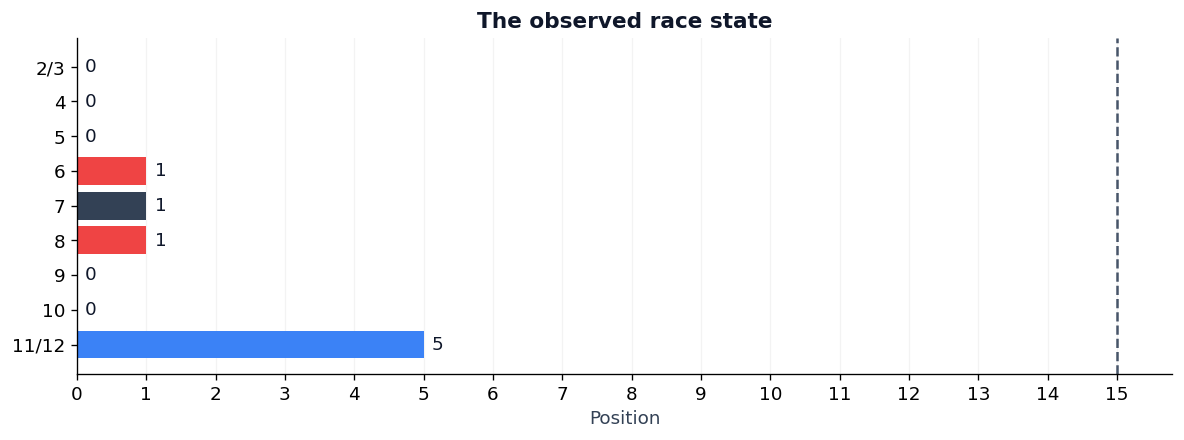

Horse,2/3,4,5,6,7,8,9,10,11/12
Win,3.4%,3.3%,7.3%,17.1%,20.7%,18.0%,7.8%,3.4%,19.0%
Place,9.2%,9.1%,18.1%,37.5%,45.8%,38.9%,18.4%,9.1%,43.0%
Show,15.3%,15.1%,28.4%,53.4%,64.0%,55.1%,28.5%,15.1%,60.9%


Horse,2/3,4,5,6,7,8,9,10,11/12
Win,-1.3,-1.5,-3.8,-1.1,-1.5,-0.5,-3.4,-1.2,+14.3
Place,-3.3,-3.8,-7.7,-1.7,-1.8,-0.3,-6.9,-3.5,+30.3
Show,-5.0,-6.0,-10.0,-1.5,-1.5,+0.0,-9.3,-5.4,+40.4


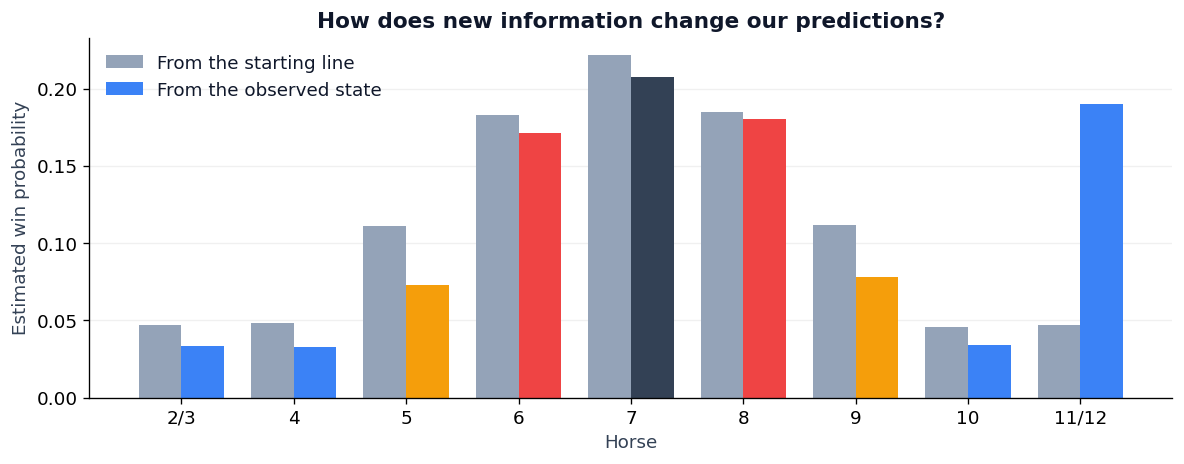

In [ ]:
#@title Continue the observed race
HISTORY_CHOICE = "8 was last" #@param ["11/12 was last", "8 was last"]
histories = {
    "11/12 was last": [6, 8, 7, 11, 12],
    "8 was last": [11, 12, 6, 7, 8],
}
observed_totals = histories[HISTORY_CHOICE]
state = trace_rolls(observed_totals)
print("Observed totals:", observed_totals)
print(f"Previous horse: {state['previous_horse']} · consecutive selections: "
      f"{state['previous_streak']}")
show_table(state["trace"], "How we reached this state")
plot_start(state["positions"])
later = simulate_races(
    n_races=N_RACES, seed=SEED + 1,
    initial_positions=state["positions"],
    previous_horse=state["previous_horse"],
    previous_streak=state["previous_streak"],
)
show_probabilities(later, f"Observed state · {N_RACES:,} simulated continuations")
change = 100 * (probability_table(later) - probability_table(baseline))
show_table(change.T, "Change from starting line · percentage points", "{:+.1f}")
compare_win_probabilities(baseline, later)


In [ ]:
#@title Rank 5-token bets using the updated probabilities
later_ranking = show_bet_ranking(
    later, SPOTS, 5, "Observed state · 5 token · recorded open spots only"
)


,Bet,Horse,Probability,Win gain,Loss,Expected gain
Spot,,,,,,
blue,Blue wins,,29.3%,25,1,+6.616
7-low,7 fifth or worse,,21.5%,20,0,+4.309
red,Red wins,,34.5%,10,1,+2.800
orange,Orange wins,,15.4%,15,1,+1.457
23-S2,Show,2/3,15.2%,20,3,+0.489
23-W3,Win,2/3,3.4%,45,2,-0.406
23-P2,Place,2/3,9.2%,25,3,-0.429


### Your response · Part 4B

1. How did the probabilities change? Use the displayed tables as your record,
   and describe the changes that matter for your decision.
2. Where should your 5 token go now, among the recorded open spots? What is its
   estimated expected gain? Is the same spot best as at the starting line?
3. Try the other history. The positions are identical: what information about
   recent rolls must the simulator remember?
4. In a real game, what might prevent you from taking the spot the calculation
   recommends? How would you represent that in the payout table?

**Our updated choices and explanation:** …


---
# 5 · Your investigation

Choose a question that interests your group, or invent one. Start with a
prediction, decide what you will measure, and then use the simulation to collect data.

| Possible question | A measurement you could collect |
| :--- | :--- |
| How many rolls does a race usually take? | Number of rolls in each race. |
| How far ahead is the winner? | Winner's position minus the next-highest position. |
| Where does each horse usually finish? | Final position of every horse. |
| How do bonuses change the chances of winning? | Win frequencies with bonuses on and off. |
| Does a shorter track change which horses are favored? | Win frequencies for several finish positions. |

You can also investigate waiting to bet. That question needs a model for
available spots and the betting cutoff, not just a comparison of horse probabilities.
Decide what assumptions you will use before interpreting the result as a strategy.


### Your experiment plan

**Our question:** …

**Our prediction, and why:** …

**What we will change, if anything:** …

**What we will measure in each race:** …

**How we will turn those measurements into an answer:** …

**What assumptions does this experiment make?** …


,Value
Mean,64.00
Median,65.00
10th percentile,47.00
90th percentile,80.00


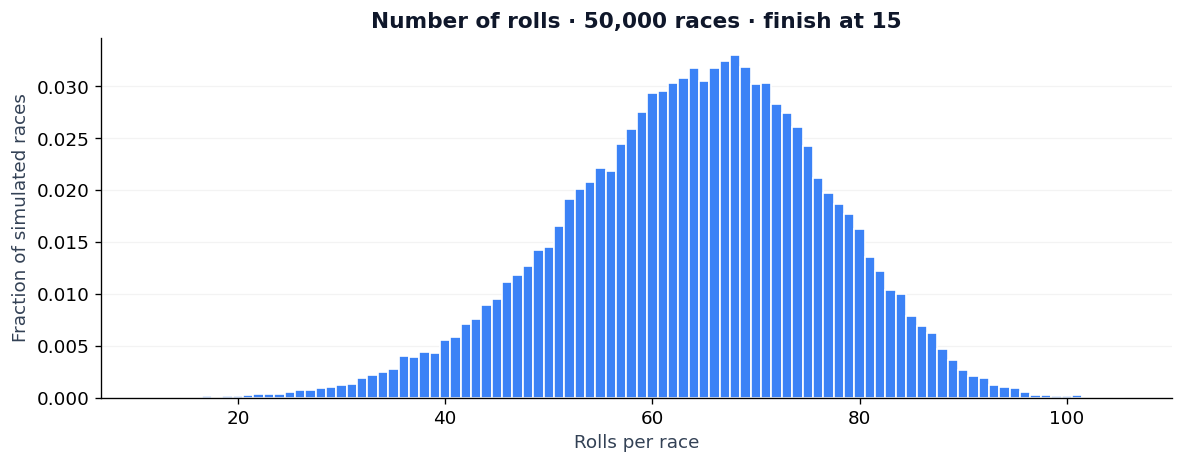

In [ ]:
#@title Investigation starter — choose a measurement and track length
QUESTION = "Number of rolls" #@param ["Number of rolls", "Winner's lead", "Final positions", "Bonuses on versus off"]
FINISH = 15 #@param {type:"slider", min:5, max:25, step:1}
study = baseline if FINISH == 15 else simulate_races(
    n_races=N_RACES, finish=FINISH, seed=SEED + 2
)

if QUESTION in {"Number of rolls", "Winner's lead"}:
    if QUESTION == "Number of rolls":
        measurements = study["rolls"]
        unit = "Rolls per race"
    else:
        runner_up = np.partition(study["positions"], -2, axis=1)[:, -2]
        measurements = study["positions"].max(axis=1) - runner_up
        unit = "Lead in spaces"
    summary = pd.DataFrame({"Value": [
        measurements.mean(), np.median(measurements),
        np.percentile(measurements, 10), np.percentile(measurements, 90),
    ]}, index=["Mean", "Median", "10th percentile", "90th percentile"])
    show_table(summary, f"{QUESTION} · finish at {FINISH}", "{:.2f}")
    bins = np.arange(measurements.min() - 0.5, measurements.max() + 1.5)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(measurements, bins=bins, weights=np.ones(len(measurements))/len(measurements),
            color="#3b82f6", edgecolor="white")
    ax.set_xlabel(unit)
    ax.set_ylabel("Fraction of simulated races")
    ax.set_title(f"{QUESTION} · {study['n_races']:,} races · finish at {FINISH}")
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()

elif QUESTION == "Final positions":
    measurements = study["positions"]
    means = measurements.mean(axis=0)
    show_table(pd.DataFrame({"Mean final position": means}, index=HORSES),
               f"Average final positions · finish at {FINISH}", "{:.2f}")
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(HORSES, means, color=COLORS)
    ax.set_xlabel("Horse")
    ax.set_ylabel("Mean position")
    ax.set_ylim(0, FINISH)
    ax.set_title("Where are the horses when the race stops?")
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()

else:
    no_bonus = simulate_races(n_races=N_RACES, finish=FINISH,
                             seed=SEED + 3, use_bonus=False)
    bonus_comparison = pd.DataFrame({
        "Bonuses on": study["win"].mean(axis=0),
        "Bonuses off": no_bonus["win"].mean(axis=0),
    }, index=HORSES)
    show_table(bonus_comparison, f"Win probabilities · finish at {FINISH}", "{:.1%}")
    x = np.arange(9)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - 0.19, bonus_comparison["Bonuses on"], 0.38, color=COLORS,
           label="Bonuses on")
    ax.bar(x + 0.19, bonus_comparison["Bonuses off"], 0.38, color="#94a3b8",
           label="Bonuses off")
    ax.set_xticks(x, HORSES)
    ax.set_xlabel("Horse")
    ax.set_ylabel("Estimated win probability")
    ax.set_title("What do bonuses change?")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()


### Your findings

**Our result, including a number or graph that supports it:** …

**Did it match our prediction? What surprised us?** …

**One limitation of our experiment:** …

**A new question we would like to investigate:** …

Prepare to share your question, method, and most interesting finding with the class.
A careful explanation of an unexpected result is a successful investigation.


## Optional workshop: try your own code

Each experiment stores its data, so you can measure something new without
rerunning the races. In the cell below, start with `baseline` for whole races
or `later` for continuations of the observed race.

| Data | Meaning |
| :--- | :--- |
| `baseline["positions"]` | One row per race; nine final positions in `HORSES` order. |
| `baseline["rolls"]` | Total rolls in each full race. |
| `baseline["winner"]` | Winning horse's index, from 0 through 8. |
| `baseline["win"]`, `["place"]`, `["show"]` | One True/False result for each race and horse. |
| `later["rolls"]` | Additional rolls **after** the observed history. |

For example, `baseline["positions"][:, HORSE_INDEX["7"]]` gives the 7 horse's
final position in every race. `.mean()` finds an average. Ask for help if you
know what you want to measure but do not yet know how to express it in Python.


In [ ]:
# Your group's workspace: edit or add code here.
# This preview shows the first five races, rather than all the data.
preview = pd.DataFrame(baseline["positions"][:5], columns=HORSES)
preview["Rolls"] = baseline["rolls"][:5]
preview["Winner"] = [HORSES[i] for i in baseline["winner"][:5]]
show_table(preview, "First five full races · use these to understand the data")


---
## Save your work

- Finish the response cells and keep the outputs that support your conclusions.
- If you change a control or the payout table, rerun the calculations that use it.
  Earlier outputs do not update automatically.
- For a final check, use **Runtime → Run all**. Your written responses stay in place.
- Save your notebook to Drive. You can download an `.ipynb` copy from the
  **File → Download** menu. Follow your instructor's submission instructions.


See [Colab's FAQ](https://research.google.com/colaboratory/faq.html) for notebook
upload, storage, and sharing.
